In [1]:
import sys
!{sys.executable} -m pip install tensorflow matplotlib seaborn scikit-learn pandas

  Using cached tensorflow-2.22.0rc1-cp314-cp314-win_amd64.whl.metadata (4.6 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached wrapt-2.5.2-cp314-cp314-win_amd64.whl.metadata (7.7 kB)
  Using cached grpcio-1.85.3-cp314-cp314-win_amd64.whl.metadata (3.9 kB)
  Using cached k


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


=== Distribución de imágenes por clase (EDA / Input Bias) ===


,Clase,Train,Test,Total,% Train
0,buildings,2191,437,2628,15.61
1,forest,2271,474,2745,16.18
2,glacier,2404,553,2957,17.13
3,mountain,2512,525,3037,17.90
4,sea,2274,510,2784,16.20
5,street,2382,501,2883,16.97


Found 14034 files belonging to 6 classes.


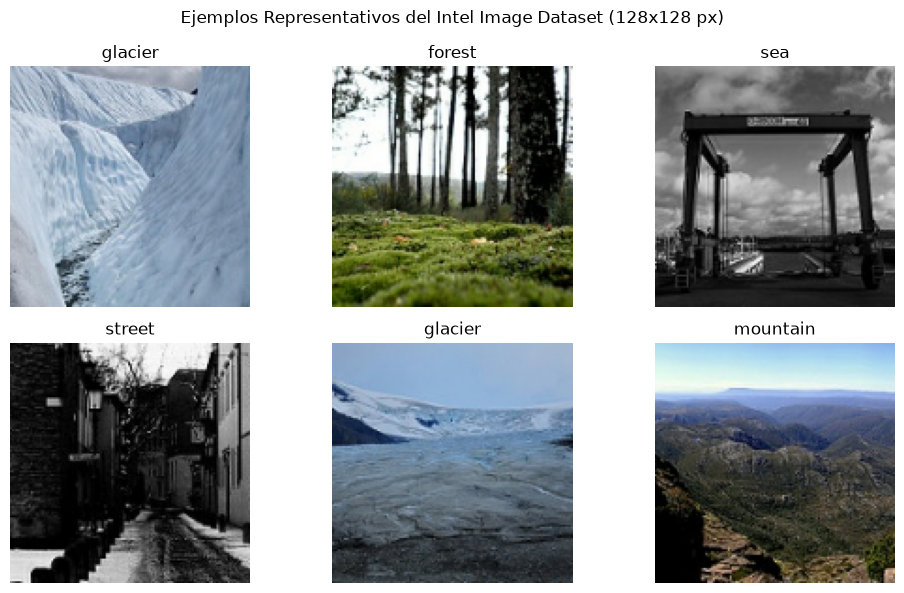

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.

Clases detectadas (6): ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

# Semilla global para reproducibilidad del pipeline
SEED = 42
tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

# Configuración general de datos y preprocesamiento
TRAIN_DIR = "../data/seg_train/seg_train"
TEST_DIR = "../data/seg_test/seg_test"
BATCH_SIZE = 32
IMG_SIZE = (128, 128)
AUTOTUNE = tf.data.AUTOTUNE


def auditar_distribucion_clases(train_dir, test_dir):
    """Realiza un EDA básico de conteo de imágenes por clase para detectar desbalances (Input Bias)."""
    filas = []
    clases = sorted([
        d for d in os.listdir(train_dir)
        if os.path.isdir(os.path.join(train_dir, d))
    ])
    for clase in clases:
        n_train = len(os.listdir(os.path.join(train_dir, clase)))
        test_clase_dir = os.path.join(test_dir, clase)
        n_test = len(os.listdir(test_clase_dir)) if os.path.isdir(test_clase_dir) else 0
        filas.append({
            "Clase": clase,
            "Train": n_train,
            "Test": n_test,
            "Total": n_train + n_test
        })
    df_dist = pd.DataFrame(filas)
    df_dist["% Train"] = (df_dist["Train"] / df_dist["Train"].sum() * 100).round(2)
    return df_dist


def construir_data_augmentation():
    """Define transformaciones geométricas aplicadas exclusivamente sobre el conjunto de entrenamiento."""
    return tf.keras.Sequential([
        layers.RandomFlip("horizontal", name="aug_flip"),
        layers.RandomRotation(0.08, name="aug_rotation"),
        layers.RandomZoom(0.08, name="aug_zoom"),
    ], name="data_augmentation")


def cargar_y_preprocesar_datos(train_dir, test_dir, img_size=(128, 128), batch_size=32, seed=42):
    """Carga datasets de entrenamiento, validación y prueba, normaliza y aplica augmentation en train."""
    train_ds = tf.keras.utils.image_dataset_from_directory(
        train_dir,
        validation_split=0.2,
        subset="training",
        shuffle=True,
        batch_size=batch_size,
        image_size=img_size,
        seed=seed
    )

    val_ds = tf.keras.utils.image_dataset_from_directory(
        train_dir,
        validation_split=0.2,
        subset="validation",
        shuffle=True,
        batch_size=batch_size,
        image_size=img_size,
        seed=seed
    )

    test_ds = tf.keras.utils.image_dataset_from_directory(
        test_dir,
        shuffle=False,
        batch_size=batch_size,
        image_size=img_size,
        seed=seed
    )

    class_names = train_ds.class_names

    # MobileNetV2 espera valores de píxel escalados en [-1, 1]
    normalization_layer = layers.Rescaling(2.0 / 255.0, offset=-1.0, name="rescaling_mobilenet")
    data_augmentation = construir_data_augmentation()

    train_ds = (
        train_ds
        .map(lambda x, y: (normalization_layer(x), y), num_parallel_calls=AUTOTUNE)
        .cache()
        .map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
        .prefetch(AUTOTUNE)
    )
    val_ds = (
        val_ds
        .map(lambda x, y: (normalization_layer(x), y), num_parallel_calls=AUTOTUNE)
        .cache()
        .prefetch(AUTOTUNE)
    )
    test_ds = (
        test_ds
        .map(lambda x, y: (normalization_layer(x), y), num_parallel_calls=AUTOTUNE)
        .cache()
        .prefetch(AUTOTUNE)
    )

    return train_ds, val_ds, test_ds, class_names


def visualizar_ejemplos(dataset_crudo, class_names, img_size):
    """Muestra ejemplos representativos del dataset antes del escalado [-1, 1]."""
    plt.figure(figsize=(10, 6))
    for images, labels in dataset_crudo.take(1):
        for i in range(min(6, len(images))):
            ax = plt.subplot(2, 3, i + 1)
            plt.imshow(images[i].numpy().astype("uint8"))
            plt.title(class_names[labels[i]])
            plt.axis("off")
    plt.suptitle(f"Ejemplos Representativos del Intel Image Dataset ({img_size[0]}x{img_size[1]} px)")
    plt.tight_layout()
    plt.show()


# --- Ejecución del Bloque 1 ---
df_distribucion = auditar_distribucion_clases(TRAIN_DIR, TEST_DIR)
print("=== Distribución de imágenes por clase (EDA / Input Bias) ===")
display(df_distribucion)

raw_preview_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    seed=SEED
)
class_names_preview = raw_preview_ds.class_names
visualizar_ejemplos(raw_preview_ds, class_names_preview, IMG_SIZE)

train_dataset, val_dataset, test_dataset, class_names = cargar_y_preprocesar_datos(
    TRAIN_DIR, TEST_DIR, img_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=SEED
)
print(f"\nClases detectadas ({len(class_names)}): {class_names}")

In [2]:
import tensorflow as tf
from tensorflow.keras import models, layers
from tensorflow.keras.applications import MobileNetV2

INPUT_SHAPE = (IMG_SIZE[0], IMG_SIZE[1], 3)
NUM_CLASSES = len(class_names)


def construir_cnn_transfer_learning(
    input_shape=INPUT_SHAPE,
    num_classes=NUM_CLASSES,
    dense_units=256,
    dropout_rate=0.4,
    l2_reg=1e-4,
    learning_rate=0.001
):
    """Construye la CNN con MobileNetV2 (128x128) y regularización en la cabeza clasificadora."""
    print("Cargando modelo base pre-entrenado (MobileNetV2)...")

    # 1. Cargar MobileNetV2 sin su cabeza original (include_top=False) adaptado a 128x128x3
    base_model = MobileNetV2(
        input_shape=input_shape,
        include_top=False,
        weights="imagenet"
    )

    # Congelamos el modelo base inicialmente para conservar filtros generales y evitar sobreajuste
    base_model.trainable = False

    # 2. Construcción de la cabeza de clasificación encima de MobileNetV2
    reg = tf.keras.regularizers.l2(l2_reg)
    model = models.Sequential([
        layers.Input(shape=input_shape, name="input_cnn"),
        base_model,
        layers.GlobalAveragePooling2D(name="global_avg_pool"),
        layers.BatchNormalization(name="bn_top"),
        layers.Dense(
            dense_units,
            activation="relu",
            kernel_initializer="he_normal",
            kernel_regularizer=reg,
            name="dense_hidden"
        ),
        layers.Dropout(dropout_rate, name="dropout_top"),
        layers.Dense(num_classes, activation="softmax", name="output")
    ], name="CNN_TransferLearning_Intel")

    # 3. Compilación con learning rate inicial para entrenar la cabeza clasificadora
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model, base_model


def construir_mlp_optimizada(
    input_shape=INPUT_SHAPE,
    num_classes=NUM_CLASSES,
    dense_units=256,
    dropout_rate=0.4,
    l2_reg=1e-4,
    learning_rate=0.001
):
    """Construye una MLP regularizada para comparar objetivamente contra la CNN final."""
    reg = tf.keras.regularizers.l2(l2_reg)
    mlp = models.Sequential([
        layers.Input(shape=input_shape, name="input_mlp"),
        layers.Flatten(name="flatten_mlp"),
        layers.Dense(
            dense_units,
            activation="relu",
            kernel_initializer="he_normal",
            kernel_regularizer=reg,
            name="mlp_dense_1"
        ),
        layers.BatchNormalization(name="mlp_bn_1"),
        layers.Dropout(dropout_rate, name="mlp_dropout_1"),
        layers.Dense(
            dense_units // 2,
            activation="relu",
            kernel_initializer="he_normal",
            kernel_regularizer=reg,
            name="mlp_dense_2"
        ),
        layers.BatchNormalization(name="mlp_bn_2"),
        layers.Dropout(dropout_rate * 0.5, name="mlp_dropout_2"),
        layers.Dense(num_classes, activation="softmax", name="mlp_output")
    ], name="MLP_Optimizada_Intel")

    mlp.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return mlp


# --- Ejecución del Bloque 2 ---
cnn_model, base_model = construir_cnn_transfer_learning(
    input_shape=INPUT_SHAPE,
    num_classes=NUM_CLASSES,
    dense_units=256,
    dropout_rate=0.4,
    l2_reg=1e-4,
    learning_rate=0.001
)
cnn_model.summary()

mlp_model = construir_mlp_optimizada(
    input_shape=INPUT_SHAPE,
    num_classes=NUM_CLASSES,
    dense_units=256,
    dropout_rate=0.4,
    l2_reg=1e-4,
    learning_rate=0.001
)
print("\n=== Resumen MLP Optimizada (para comparación) ===")
mlp_model.summary()

Cargando modelo base pre-entrenado (MobileNetV2)...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "CNN_TransferLearning_Intel"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_top (BatchNormalization)     │ (None, 1280)           │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden (Dense)            │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_top (Dropout)           │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,592,582 (9.89 MB)

 Trainable params: 332,038 (1.27 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_mlp (Flatten)           │ (None, 49152)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mlp_dense_1 (Dense)             │ (None, 256)            │    12,583,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mlp_bn_1 (BatchNormalization)   │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mlp_dropout_1 (Dropout)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mlp_dense_2 (Dense)             │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mlp_bn_2 (BatchNormalization)   │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mlp_dropout_2 (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mlp_output (Dense)              │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,618,374 (48.14 MB)

 Trainable params: 12,617,606 (48.13 MB)

 Non-trainable params: 768 (3.00 KB)

Fase 1: Entrenando cabeza clasificadora con base congelada...
Epoch 1/12


c:\Users\va-alumno\TLY1101-EP1-Intel-Dataset\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


351/351 ━━━━━━━━━━━━━━━━━━━━ 30s 80ms/step - accuracy: 0.8240 - loss: 0.6060 - val_accuracy: 0.9059 - val_loss: 0.3267 - learning_rate: 0.0010
Epoch 2/12
351/351 ━━━━━━━━━━━━━━━━━━━━ 29s 82ms/step - accuracy: 0.8700 - loss: 0.4178 - val_accuracy: 0.9109 - val_loss: 0.3202 - learning_rate: 0.0010
Epoch 3/12
351/351 ━━━━━━━━━━━━━━━━━━━━ 28s 80ms/step - accuracy: 0.8819 - loss: 0.3837 - val_accuracy: 0.9045 - val_loss: 0.3211 - learning_rate: 0.0010
Epoch 4/12
351/351 ━━━━━━━━━━━━━━━━━━━━ 28s 80ms/step - accuracy: 0.8906 - loss: 0.3568 - val_accuracy: 0.9152 - val_loss: 0.3025 - learning_rate: 0.0010
Epoch 5/12
351/351 ━━━━━━━━━━━━━━━━━━━━ 29s 83ms/step - accuracy: 0.8967 - loss: 0.3318 - val_accuracy: 0.9070 - val_loss: 0.3247 - learning_rate: 0.0010
Epoch 6/12
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.9008 - loss: 0.3299
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
351/351 ━━━━━━━━━━━━━━━━━━━━ 28s 80ms/step - accuracy: 0.9008 - loss: 0.3299 

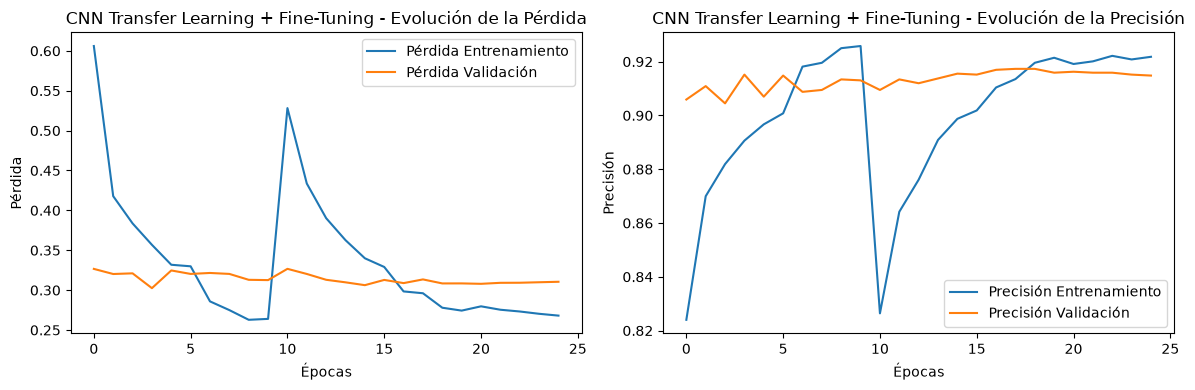

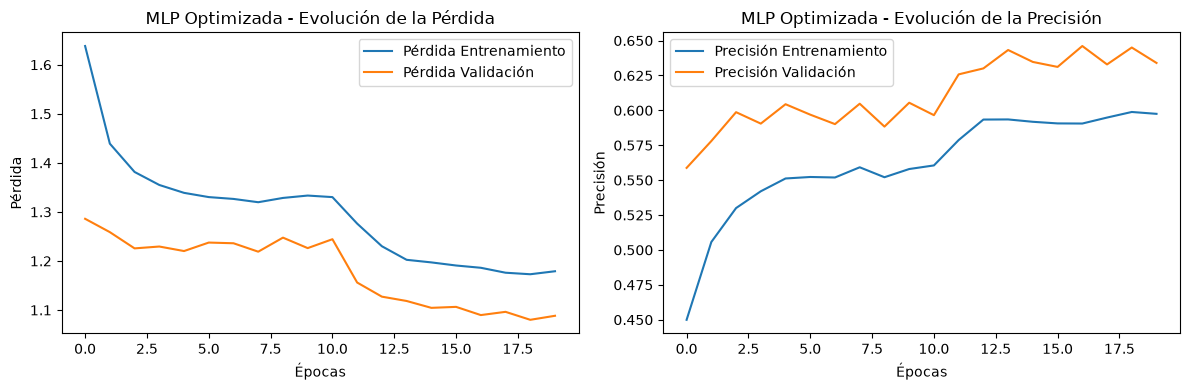

In [3]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf


def crear_callbacks(patience_es=8, patience_lr=3, min_lr=1e-6):
    """Crea callbacks de EarlyStopping y ReduceLROnPlateau para controlar sobreajuste y convergencia."""
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=patience_es,
        restore_best_weights=True,
        verbose=1
    )
    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=patience_lr,
        min_lr=min_lr,
        verbose=1
    )
    return [early_stopping, reduce_lr]


def entrenar_cnn_con_finetuning(
    model,
    base_model,
    train_ds,
    val_ds,
    epochs_head=12,
    epochs_ft=15,
    fine_tune_at=-40,
    lr_ft=1e-5
):
    """Entrena en dos fases: cabeza clasificadora congelada y ajuste fino (fine-tuning) de capas finales."""
    print("Fase 1: Entrenando cabeza clasificadora con base congelada...")
    t0 = time.time()
    hist_head = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs_head,
        callbacks=crear_callbacks(patience_es=6, patience_lr=2, min_lr=1e-6)
    )

    print("\nFase 2: Descongelando capas finales de MobileNetV2 para fine-tuning...")
    base_model.trainable = True
    for layer in base_model.layers[:fine_tune_at]:
        layer.trainable = False

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr_ft),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    hist_ft = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs_ft,
        callbacks=crear_callbacks(patience_es=8, patience_lr=3, min_lr=1e-7)
    )

    tiempo_total = time.time() - t0
    historia_combinada = {
        "loss": hist_head.history["loss"] + hist_ft.history["loss"],
        "val_loss": hist_head.history["val_loss"] + hist_ft.history["val_loss"],
        "accuracy": hist_head.history["accuracy"] + hist_ft.history["accuracy"],
        "val_accuracy": hist_head.history["val_accuracy"] + hist_ft.history["val_accuracy"],
    }
    return historia_combinada, tiempo_total


def entrenar_mlp_comparativa(model, train_ds, val_ds, epochs=20):
    """Entrena la MLP regularizada bajo condiciones comparables para contraste con la CNN."""
    print("\nEntrenando MLP optimizada para comparación objetiva...")
    t0 = time.time()
    hist = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        callbacks=crear_callbacks(patience_es=6, patience_lr=3, min_lr=1e-6)
    )
    return hist.history, time.time() - t0


def graficar_curvas_aprendizaje(history_dict, titulo_prefijo="CNN Transfer Learning"):
    """Grafica evolución de Loss y Accuracy en entrenamiento y validación."""
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history_dict["loss"], label="Pérdida Entrenamiento")
    plt.plot(history_dict["val_loss"], label="Pérdida Validación")
    plt.title(f"{titulo_prefijo} - Evolución de la Pérdida")
    plt.xlabel("Épocas")
    plt.ylabel("Pérdida")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history_dict["accuracy"], label="Precisión Entrenamiento")
    plt.plot(history_dict["val_accuracy"], label="Precisión Validación")
    plt.title(f"{titulo_prefijo} - Evolución de la Precisión")
    plt.xlabel("Épocas")
    plt.ylabel("Precisión")
    plt.legend()

    plt.tight_layout()
    plt.show()


# --- Ejecución del Bloque 3 ---
history_cnn, tiempo_cnn = entrenar_cnn_con_finetuning(
    cnn_model, base_model, train_dataset, val_dataset,
    epochs_head=12, epochs_ft=15, fine_tune_at=-40, lr_ft=1e-5
)
print(f"\nEntrenamiento CNN finalizado en {tiempo_cnn:.2f} segundos.")

history_mlp, tiempo_mlp = entrenar_mlp_comparativa(
    mlp_model, train_dataset, val_dataset, epochs=20
)
print(f"\nEntrenamiento MLP finalizado en {tiempo_mlp:.2f} segundos.")

os.makedirs("../models", exist_ok=True)
cnn_model.save("../models/cnn_intel_model.keras")
mlp_model.save("../models/mlp_intel_model.keras")
print("Modelos guardados en '../models/cnn_intel_model.keras' y '../models/mlp_intel_model.keras'")

graficar_curvas_aprendizaje(history_cnn, "CNN Transfer Learning + Fine-Tuning")
graficar_curvas_aprendizaje(history_mlp, "MLP Optimizada")

Generando predicciones de la CNN (Transfer Learning) sobre el set de prueba...

--- REPORTE DE CLASIFICACIÓN - CNN TRANSFER LEARNING ---
              precision    recall  f1-score   support

   buildings       0.91      0.90      0.90       437
      forest       0.99      0.99      0.99       474
     glacier       0.86      0.82      0.84       553
    mountain       0.86      0.85      0.85       525
         sea       0.92      0.97      0.94       510
      street       0.91      0.92      0.91       501

    accuracy                           0.91      3000
   macro avg       0.91      0.91      0.91      3000
weighted avg       0.91      0.91      0.91      3000



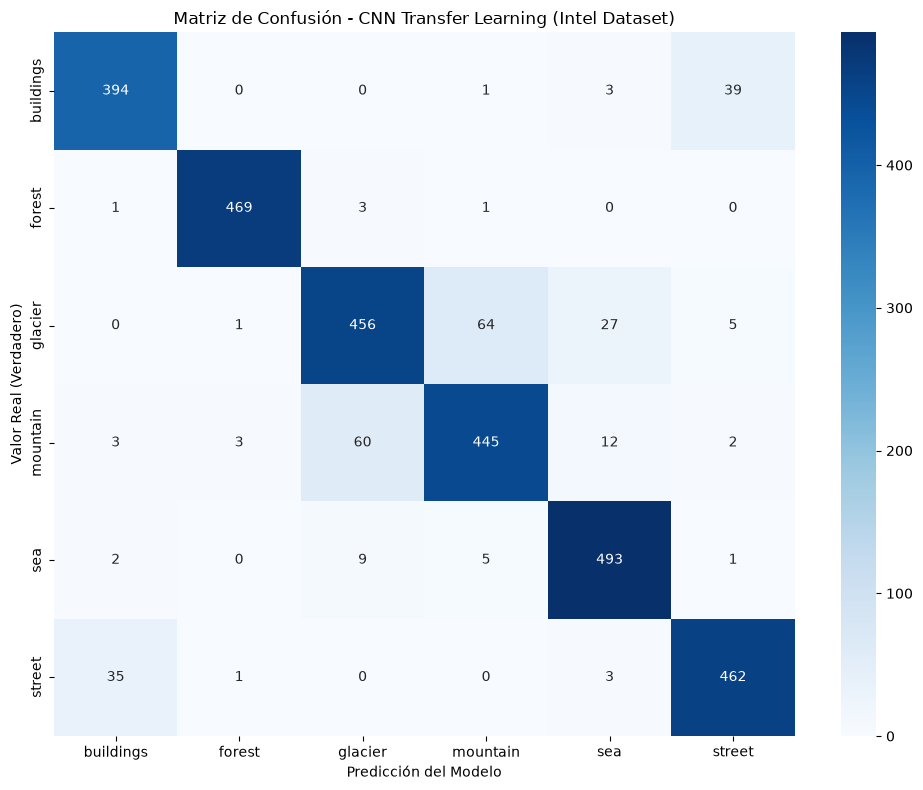


--- REPORTE DE CLASIFICACIÓN - MLP ---
              precision    recall  f1-score   support

   buildings       0.59      0.41      0.48       437
      forest       0.79      0.78      0.78       474
     glacier       0.58      0.69      0.63       553
    mountain       0.58      0.67      0.62       525
         sea       0.56      0.43      0.49       510
      street       0.64      0.74      0.69       501

    accuracy                           0.62      3000
   macro avg       0.63      0.62      0.62      3000
weighted avg       0.62      0.62      0.62      3000



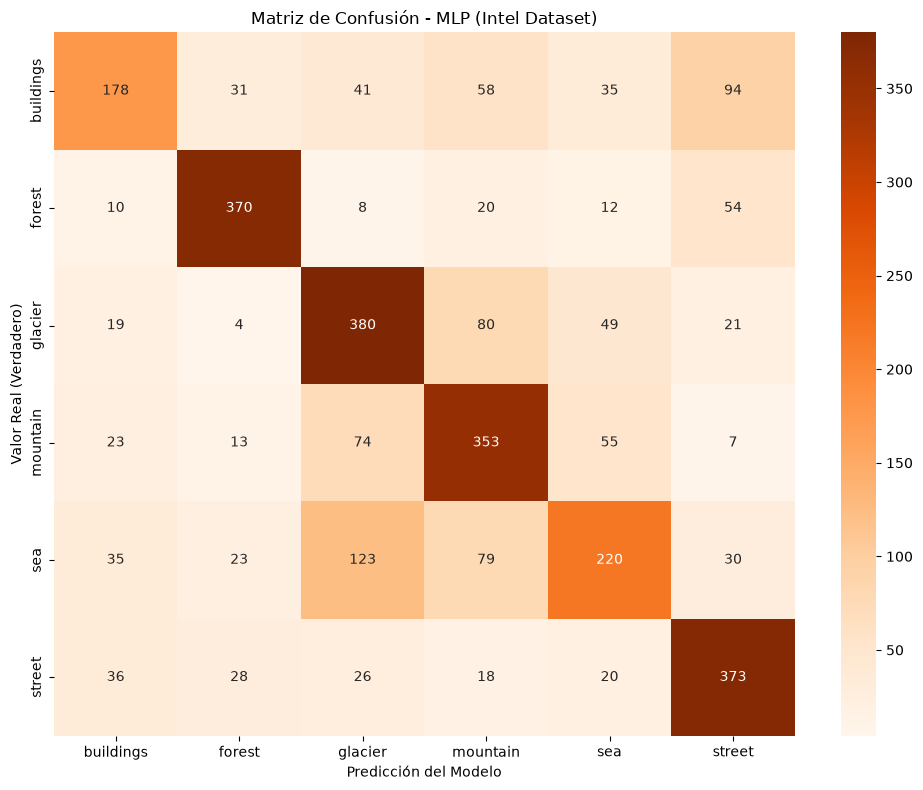


=== TABLA COMPARATIVA: MLP vs CNN TRANSFER LEARNING ===


,Métrica / Característica,Modelo MLP,Modelo CNN Final (Transfer Learning)
0,Cantidad Total de Parámetros,"12,618,374","2,592,582"
1,Tiempo de Entrenamiento (s),590.19,909.56
2,Accuracy (Prueba),0.6247,0.9063
3,Precision Macro,0.6251,0.9075
4,Recall Macro,0.6206,0.9087
5,F1-Score Macro,0.6167,0.9079


In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


def obtener_predicciones_y_metricas(model, dataset, class_names, nombre_modelo="Modelo"):
    """Evalúa un modelo sobre un dataset y calcula métricas globales, macro, reporte y matriz de confusión."""
    y_true = []
    y_probs = []

    for images, labels in dataset:
        y_true.extend(labels.numpy())
        preds = model.predict(images, verbose=0)
        y_probs.extend(preds)

    y_true = np.array(y_true)
    y_pred = np.argmax(y_probs, axis=1)

    metricas = {
        "modelo": nombre_modelo,
        "parametros": f"{model.count_params():,}",
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "y_true": y_true,
        "y_pred": y_pred,
        "y_probs": np.array(y_probs),
        "cm": confusion_matrix(y_true, y_pred),
        "reporte": classification_report(y_true, y_pred, target_names=class_names, zero_division=0)
    }
    return metricas


def graficar_matriz_confusion(cm, class_names, titulo="Matriz de Confusión", cmap="Blues"):
    """Genera una visualización limpia de la matriz de confusión."""
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap=cmap,
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title(titulo)
    plt.xlabel("Predicción del Modelo")
    plt.ylabel("Valor Real (Verdadero)")
    plt.tight_layout()
    plt.show()


def construir_tabla_comparativa(res_mlp, res_cnn, t_mlp=None, t_cnn=None):
    """Construye una tabla comparativa objetiva entre la MLP y la CNN final."""
    filas_metricas = [
        "Cantidad Total de Parámetros",
        "Tiempo de Entrenamiento (s)",
        "Accuracy (Prueba)",
        "Precision Macro",
        "Recall Macro",
        "F1-Score Macro"
    ]
    col_mlp = [
        res_mlp["parametros"],
        f"{t_mlp:.2f}" if t_mlp is not None else "N/D",
        f"{res_mlp['accuracy']:.4f}",
        f"{res_mlp['precision_macro']:.4f}",
        f"{res_mlp['recall_macro']:.4f}",
        f"{res_mlp['f1_macro']:.4f}"
    ]
    col_cnn = [
        res_cnn["parametros"],
        f"{t_cnn:.2f}" if t_cnn is not None else "N/D",
        f"{res_cnn['accuracy']:.4f}",
        f"{res_cnn['precision_macro']:.4f}",
        f"{res_cnn['recall_macro']:.4f}",
        f"{res_cnn['f1_macro']:.4f}"
    ]
    return pd.DataFrame({
        "Métrica / Característica": filas_metricas,
        "Modelo MLP": col_mlp,
        "Modelo CNN Final (Transfer Learning)": col_cnn
    })


# --- Ejecución del Bloque 4 ---
print("Generando predicciones de la CNN (Transfer Learning) sobre el set de prueba...")
res_cnn = obtener_predicciones_y_metricas(cnn_model, test_dataset, class_names, nombre_modelo="CNN")

print("\n--- REPORTE DE CLASIFICACIÓN - CNN TRANSFER LEARNING ---")
print(res_cnn["reporte"])

graficar_matriz_confusion(
    res_cnn["cm"],
    class_names,
    titulo="Matriz de Confusión - CNN Transfer Learning (Intel Dataset)",
    cmap="Blues"
)

mlp_path = "../models/mlp_intel_model.keras"
modelo_mlp_eval = None

if "mlp_model" in globals() and mlp_model is not None:
    modelo_mlp_eval = mlp_model
elif os.path.exists(mlp_path):
    print("\nCargando modelo MLP guardado en '../models/mlp_intel_model.keras' para comparación...")
    modelo_mlp_eval = tf.keras.models.load_model(mlp_path)

if modelo_mlp_eval is not None:
    res_mlp = obtener_predicciones_y_metricas(modelo_mlp_eval, test_dataset, class_names, nombre_modelo="MLP")
    print("\n--- REPORTE DE CLASIFICACIÓN - MLP ---")
    print(res_mlp["reporte"])

    graficar_matriz_confusion(
        res_mlp["cm"],
        class_names,
        titulo="Matriz de Confusión - MLP (Intel Dataset)",
        cmap="Oranges"
    )

    t_mlp_val = globals().get("tiempo_mlp", None)
    t_cnn_val = globals().get("tiempo_cnn", None)
    comparacion = construir_tabla_comparativa(res_mlp, res_cnn, t_mlp=t_mlp_val, t_cnn=t_cnn_val)

    print("\n=== TABLA COMPARATIVA: MLP vs CNN TRANSFER LEARNING ===")
    display(comparacion)
else:
    print("Nota: No se encontró 'mlp_model' en memoria ni '../models/mlp_intel_model.keras'.")


--- Ejecutando experimento: Exp 1: Base (LR=1e-3, Drop=0.4) ---
Cargando modelo base pre-entrenado (MobileNetV2)...


c:\Users\va-alumno\TLY1101-EP1-Intel-Dataset\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(



--- Ejecutando experimento: Exp 2: Variación LR (LR=5e-4) ---
Cargando modelo base pre-entrenado (MobileNetV2)...


c:\Users\va-alumno\TLY1101-EP1-Intel-Dataset\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(



--- Ejecutando experimento: Exp 3: Variación Drop (Drop=0.2) ---
Cargando modelo base pre-entrenado (MobileNetV2)...


c:\Users\va-alumno\TLY1101-EP1-Intel-Dataset\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(



--- Ejecutando experimento: Exp 4: Variación Capacidad (128) ---
Cargando modelo base pre-entrenado (MobileNetV2)...


c:\Users\va-alumno\TLY1101-EP1-Intel-Dataset\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(



=== TABLA COMPARATIVA DE EXPERIMENTACIÓN CONTROLADA ===


,Configuración,Learning Rate,Dropout,Unidades Densas,Train Acc (Final),Val Acc (Mejor),Test Accuracy,Test F1-Macro,Tiempo (s)
0,"Exp 1: Base (LR=1e-3, Drop=0.4)",0.0010,0.4,256,0.9051,0.9159,0.9110,0.9128,200.72
1,Exp 2: Variación LR (LR=5e-4),0.0005,0.4,256,0.9027,0.9102,0.9070,0.9081,223.37
2,Exp 3: Variación Drop (Drop=0.2),0.0010,0.2,256,0.9145,0.9091,0.9077,0.9093,263.95
3,Exp 4: Variación Capacidad (128),0.0010,0.4,128,0.8951,0.9170,0.9100,0.9115,199.92


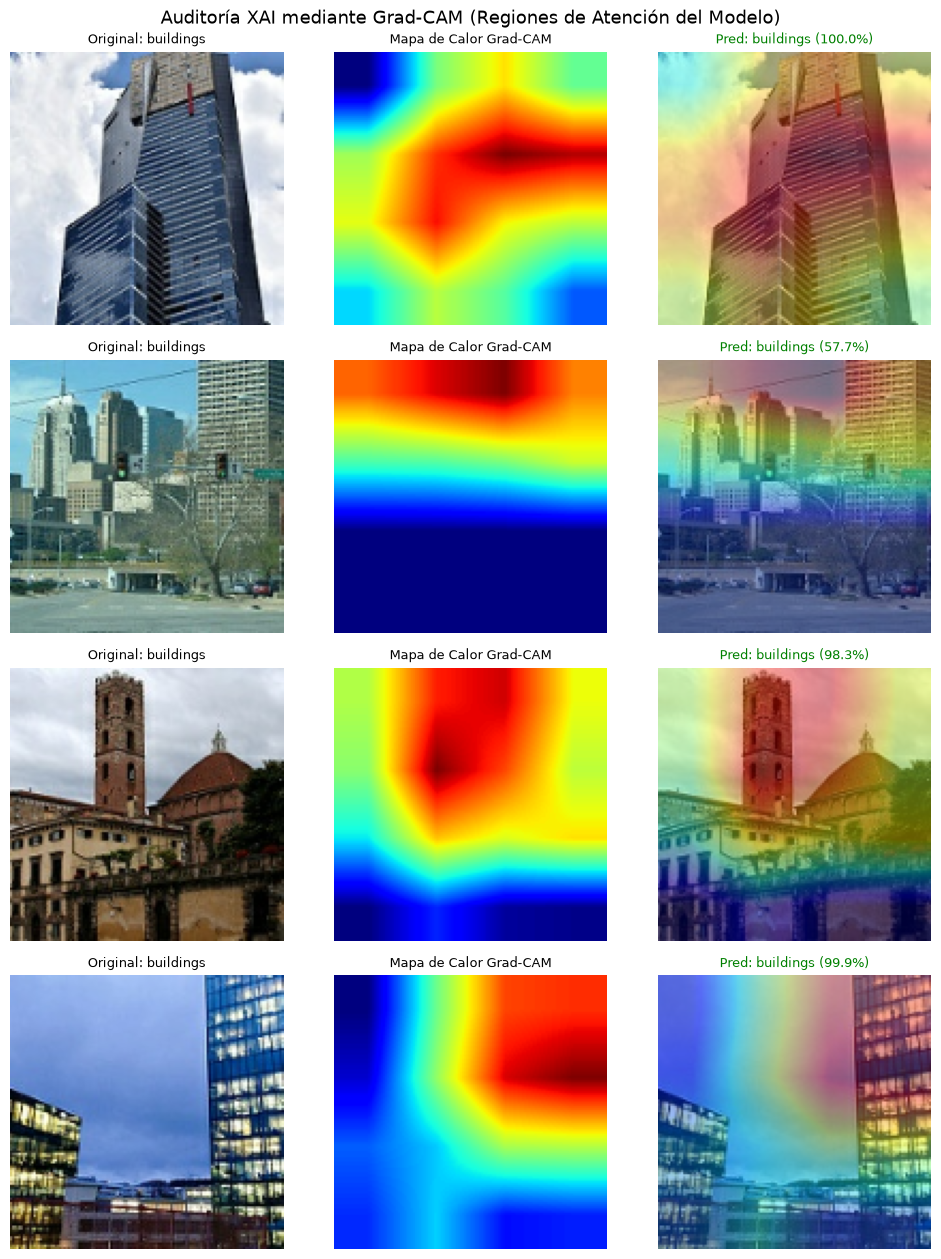

In [5]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import accuracy_score, f1_score


# ==============================================================================
# BLOQUE 5: OPTIMIZACIÓN CONTROLADA DE HIPERPARÁMETROS (EXPERIMENTACIÓN)
# ==============================================================================

def ejecutar_experimento_hiperparametros(train_ds, val_ds, test_ds, configs, epochs_exp=6):
    """
    Evalúa configuraciones modificando un hiperparámetro a la vez (experimentación controlada).
    Utiliza pocos epochs en fase de exploración para comparar convergencia y generalización
    sin disparar el costo computacional.
    """
    resultados = []

    for cfg in configs:
        print(f"\n--- Ejecutando experimento: {cfg['Experimento']} ---")
        tf.keras.utils.set_random_seed(42)

        modelo_exp, _ = construir_cnn_transfer_learning(
            input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
            num_classes=len(class_names),
            dense_units=cfg["dense_units"],
            dropout_rate=cfg["dropout"],
            l2_reg=1e-4,
            learning_rate=cfg["lr"]
        )

        t0 = time.time()
        hist = modelo_exp.fit(
            train_ds,
            validation_data=val_ds,
            epochs=epochs_exp,
            verbose=0
        )
        tiempo_exp = time.time() - t0

        # Evaluación objetiva en Test
        y_true_exp, y_pred_exp = [], []
        for x_b, y_b in test_ds:
            y_true_exp.extend(y_b.numpy())
            preds = modelo_exp.predict(x_b, verbose=0)
            y_pred_exp.extend(np.argmax(preds, axis=1))

        acc_test = accuracy_score(y_true_exp, y_pred_exp)
        f1_test = f1_score(y_true_exp, y_pred_exp, average="macro", zero_division=0)
        best_val_acc = max(hist.history["val_accuracy"])
        final_train_acc = hist.history["accuracy"][-1]

        resultados.append({
            "Configuración": cfg["Experimento"],
            "Learning Rate": cfg["lr"],
            "Dropout": cfg["dropout"],
            "Unidades Densas": cfg["dense_units"],
            "Train Acc (Final)": round(final_train_acc, 4),
            "Val Acc (Mejor)": round(best_val_acc, 4),
            "Test Accuracy": round(acc_test, 4),
            "Test F1-Macro": round(f1_test, 4),
            "Tiempo (s)": round(tiempo_exp, 2)
        })

    return pd.DataFrame(resultados)


# Grilla controlada: varía un hiperparámetro a la vez respecto a la configuración base
configuraciones_estudio = [
    {"Experimento": "Exp 1: Base (LR=1e-3, Drop=0.4)", "lr": 1e-3, "dropout": 0.4, "dense_units": 256},
    {"Experimento": "Exp 2: Variación LR (LR=5e-4)",   "lr": 5e-4, "dropout": 0.4, "dense_units": 256},
    {"Experimento": "Exp 3: Variación Drop (Drop=0.2)","lr": 1e-3, "dropout": 0.2, "dense_units": 256},
    {"Experimento": "Exp 4: Variación Capacidad (128)","lr": 1e-3, "dropout": 0.4, "dense_units": 128},
]

df_experimentos = ejecutar_experimento_hiperparametros(
    train_dataset, val_dataset, test_dataset, configuraciones_estudio, epochs_exp=6
)

print("\n=== TABLA COMPARATIVA DE EXPERIMENTACIÓN CONTROLADA ===")
display(df_experimentos)


# ==============================================================================
# BLOQUE 6: AUDITORÍA Y EXPLICABILIDAD CON GRAD-CAM (XAI)
# ==============================================================================

def calcular_gradcam_mobilenet(cnn_model, base_model, img_tensor, class_index=None):
    """
    Calcula el mapa de activación de clase ponderado por gradientes (Grad-CAM)
    sobre la última capa convolucional de MobileNetV2.
    """
    # Localizar la última capa Conv2D dentro de MobileNetV2
    last_conv = next(
        layer for layer in reversed(base_model.layers)
        if isinstance(layer, layers.Conv2D)
    )

    # Sub-modelo que entrega activaciones convolucionales y salida del backbone
    grad_backbone = models.Model(
        inputs=base_model.inputs,
        outputs=[last_conv.output, base_model.output]
    )

    # Capas superiores de clasificación (GlobalAvgPool -> BN -> Dense -> Dropout -> Output)
    head_layers = cnn_model.layers[1:]

    with tf.GradientTape() as tape:
        conv_outputs, x = grad_backbone(img_tensor, training=False)
        for layer in head_layers:
            x = layer(x, training=False)
        preds = x

        if class_index is None:
            class_index = tf.argmax(preds[0])
        class_channel = preds[:, class_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), int(class_index), float(preds[0][class_index])


def visualizar_auditoria_gradcam(cnn_model, base_model, dataset, class_names, n_muestras=4):
    """Superpone mapas de calor Grad-CAM sobre imágenes de prueba para auditar dónde mira el modelo."""
    for images, labels in dataset.take(1):
        sample_imgs = images[:n_muestras]
        sample_lbls = labels[:n_muestras]
        break

    fig, axes = plt.subplots(n_muestras, 3, figsize=(10, 3.2 * n_muestras))
    fig.suptitle("Auditoría XAI mediante Grad-CAM (Regiones de Atención del Modelo)", fontsize=13)

    for i in range(n_muestras):
        img_tensor = sample_imgs[i:i+1]
        real_idx = int(sample_lbls[i].numpy())
        heatmap, pred_idx, conf = calcular_gradcam_mobilenet(cnn_model, base_model, img_tensor)

        # Convertir imagen de [-1, 1] a [0, 1]
        img_vis = np.clip((sample_imgs[i].numpy() + 1.0) / 2.0, 0.0, 1.0)

        # Redimensionar heatmap al tamaño de la imagen original
        heatmap_resized = tf.image.resize(heatmap[..., tf.newaxis], (IMG_SIZE[0], IMG_SIZE[1])).numpy().squeeze()
        cmap = plt.get_cmap("jet")
        heatmap_color = cmap(heatmap_resized)[..., :3]
        superpuesta = np.clip(0.6 * img_vis + 0.4 * heatmap_color, 0.0, 1.0)

        color_titulo = "green" if pred_idx == real_idx else "red"

        axes[i, 0].imshow(img_vis)
        axes[i, 0].set_title(f"Original: {class_names[real_idx]}", fontsize=9)
        axes[i, 0].axis("off")

        axes[i, 1].imshow(heatmap_resized, cmap="jet")
        axes[i, 1].set_title("Mapa de Calor Grad-CAM", fontsize=9)
        axes[i, 1].axis("off")

        axes[i, 2].imshow(superpuesta)
        axes[i, 2].set_title(f"Pred: {class_names[pred_idx]} ({conf*100:.1f}%)", color=color_titulo, fontsize=9)
        axes[i, 2].axis("off")

    plt.tight_layout()
    plt.show()


# --- Ejecución de Auditoría Grad-CAM ---
visualizar_auditoria_gradcam(cnn_model, base_model, test_dataset, class_names, n_muestras=4)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models


def _a_rango_visual(img):
    """Convierte una imagen normalizada en [-1, 1] al rango [0, 1] para visualizar con matplotlib."""
    return np.clip((img + 1.0) / 2.0, 0.0, 1.0)


def visualizar_feature_maps_mobilenet(cnn_model, base_model, dataset, class_names, num_filtros=4):
    """Extrae activaciones de capas convolucionales de MobileNetV2 para interpretar qué patrones detecta."""
    for images, labels in dataset.take(1):
        sample_image = images[0:1]
        sample_label = class_names[int(labels[0].numpy())]
        break

    # Seleccionar 3 capas Conv2D distribuidas (inicial, intermedia y profunda) dentro de MobileNetV2
    conv_layers = [layer for layer in base_model.layers if isinstance(layer, layers.Conv2D)]
    if len(conv_layers) >= 3:
        indices = [0, len(conv_layers) // 2, len(conv_layers) - 1]
        selected_layers = [conv_layers[i] for i in indices]
    else:
        selected_layers = conv_layers

    layer_names = [layer.name for layer in selected_layers]
    feature_map_model = models.Model(
        inputs=base_model.inputs,
        outputs=[layer.output for layer in selected_layers]
    )
    feature_maps = feature_map_model.predict(sample_image, verbose=0)

    plt.figure(figsize=(3.5, 3.5))
    plt.imshow(_a_rango_visual(sample_image[0].numpy()))
    plt.title(f"Imagen Original: {sample_label}")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    n_rows = len(selected_layers)
    n_cols = num_filtros
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 3 * n_rows))
    fig.suptitle(f"Activaciones Jerárquicas en MobileNetV2 (Clase: {sample_label})", fontsize=13)

    if n_rows == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, (name, fmap) in enumerate(zip(layer_names, feature_maps)):
        max_f = min(n_cols, fmap.shape[-1])
        for col in range(max_f):
            ax = axes[row, col]
            ax.imshow(fmap[0, :, :, col], cmap="viridis")
            ax.set_title(f"{name} (Filtro {col + 1})", fontsize=9)
            ax.axis("off")

    plt.tight_layout()
    plt.show()


def analizar_aciertos_y_errores(test_dataset, class_names, y_true, y_pred, y_probs, n_ejemplos=3):
    """Muestra ejemplos de predicciones correctas e incorrectas junto con su confianza para auditoría."""
    all_test_images = np.concatenate([x.numpy() for x, _ in test_dataset], axis=0)
    correct_idx = np.where(y_pred == y_true)[0]
    incorrect_idx = np.where(y_pred != y_true)[0]

    plt.figure(figsize=(12, 6))

    for i, idx in enumerate(correct_idx[:n_ejemplos]):
        ax = plt.subplot(2, n_ejemplos, i + 1)
        plt.imshow(_a_rango_visual(all_test_images[idx]))
        conf = np.max(y_probs[idx]) * 100
        plt.title(
            f"ACIERTO\nReal: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]} ({conf:.1f}%)",
            color="green",
            fontsize=9
        )
        ax.axis("off")

    for i, idx in enumerate(incorrect_idx[:n_ejemplos]):
        ax = plt.subplot(2, n_ejemplos, i + 1 + n_ejemplos)
        plt.imshow(_a_rango_visual(all_test_images[idx]))
        conf = np.max(y_probs[idx]) * 100
        plt.title(
            f"ERROR\nReal: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]} ({conf:.1f}%)",
            color="red",
            fontsize=9
        )
        ax.axis("off")

    plt.suptitle("Análisis Visual de Predicciones: Correctas vs. Incorrectas", fontsize=13)
    plt.tight_layout()
    plt.show()


# --- Ejecución ---
if "res_cnn" in globals():
    y_true_eval = res_cnn["y_true"]
    y_pred_eval = res_cnn["y_pred"]
    y_probs_eval = res_cnn["y_probs"]
else:
    y_true_eval = y_true
    y_pred_eval = y_pred_cnn
    y_probs_eval = np.array(y_pred_probs_cnn)

visualizar_feature_maps_mobilenet(cnn_model, base_model, test_dataset, class_names, num_filtros=4)
analizar_aciertos_y_errores(test_dataset, class_names, y_true_eval, y_pred_eval, y_probs_eval, n_ejemplos=3)